In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", palette="Set2")

df = pd.read_csv(
    "../data/SeoulBikeData.csv",
    encoding="cp1252"
)

df = df[df["Functioning Day"] == "Yes"].copy()

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y"
)

df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [2]:
weather_features = [
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)",
    "Rainfall(mm)",
    "Snowfall (cm)"
]

combined_features = weather_features + ["Hour"]

X_weather = df[weather_features]
X_combined = df[combined_features]

y = df["Rented Bike Count"]

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42
)

## Linjär Regression
### Modell A - Väder

In [3]:
weather_model = LinearRegression()

weather_model.fit(
    X_weather.loc[train_idx],
    y.loc[train_idx]
)

weather_predictions = weather_model.predict(
    X_weather.loc[test_idx]
)

weather_mae = mean_absolute_error(
    y.loc[test_idx],
    weather_predictions
)

print(f"Endast väder – MAE: {weather_mae:.1f}")

Endast väder – MAE: 348.9


### Modell B - Väder + Tid

In [4]:
combined_model = LinearRegression()

combined_model.fit(
    X_combined.loc[train_idx],
    y.loc[train_idx]
)

combined_predictions = combined_model.predict(
    X_combined.loc[test_idx]
)

combined_mae = mean_absolute_error(
    y.loc[test_idx],
    combined_predictions
)

print(f"Väder + tid – MAE: {combined_mae:.1f}")


Väder + tid – MAE: 330.2


### Utvärdering – Modell A och B

Vi har jämfört två linjära regressionsmodeller för att undersöka om tidsinformation kan förbättra förutsägelsen av antalet cykeluthyrningar.

- **Modell A (endast väder):** MAE 348,9
- **Modell B (väder + klockslag):** MAE 330,2

Genom att inkludera `Hour` som ytterligare en feature minskade modellens genomsnittliga prediktionsfel med **18,7 cyklar per timme, motsvarande cirka 5,4 %**.

Resultatet visar att klockslaget tillför information som förbättrar modellens förutsägelser, men förbättringen är relativt begränsad.

## Random Forest
### Modell C - Väder + tid

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_combined.loc[train_idx],
    y.loc[train_idx]
)

rf_predictions = rf_model.predict(
    X_combined.loc[test_idx]
)

rf_mae = mean_absolute_error(
    y.loc[test_idx],
    rf_predictions
)

print(f"Random Forest – MAE: {rf_mae:.1f}")

Random Forest – MAE: 151.8


In [6]:
results = pd.DataFrame({
    "Modell": [
        "A – Endast väder",
        "B – Väder + tid",
        "C – Random Forest"
    ],
    "MAE": [
        weather_mae,
        combined_mae,
        rf_mae
    ]
})

results.round(1)

,Modell,MAE
0,A – Endast väder,348.9
1,B – Väder + tid,330.2
2,C – Random Forest,151.8


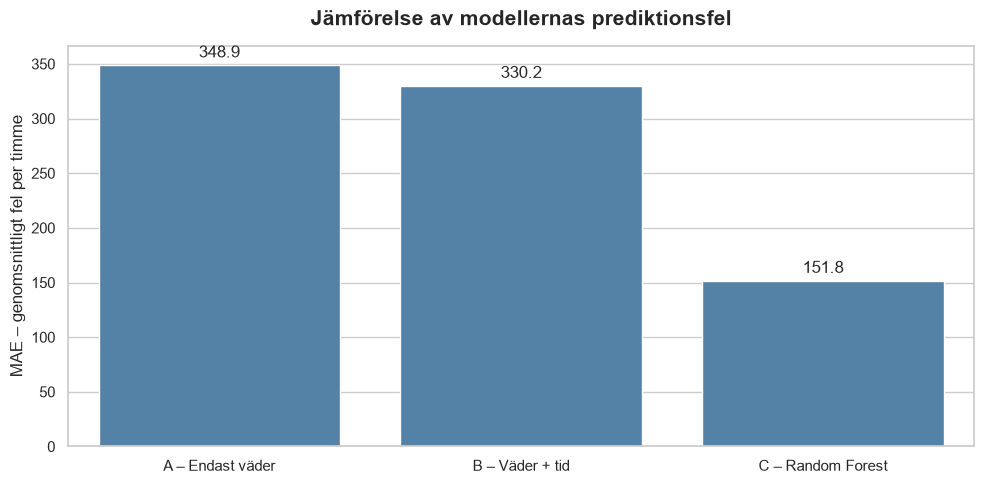

In [7]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=results,
    x="Modell",
    y="MAE",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.title(
    "Jämförelse av modellernas prediktionsfel",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("")
plt.ylabel("MAE – genomsnittligt fel per timme")

plt.tight_layout()
plt.show()


### Random Forest

Vi har jämfört linjär regression med Random Forest för att undersöka om en algoritm som kan hantera icke-linjära samband ger bättre förutsägelser.

Samtliga modeller har utvärderats på samma testdata.

**Resultat:**

- Modell A – Linjär regression (väder): MAE 348,9
- Modell B – Linjär regression (väder + tid): MAE 330,2
- Modell C – Random Forest (väder + tid): MAE 151,8

